# Course 3 — DQN-Based Budget-Constrained Channel Investigation (Corrected)

Corrections versus the first version:
* **Evaluation bug fixed.** The old code called `env.reset(options={"case": case})`, which the environment
  ignored, so the DQN acted on a *random* event while being scored on another one (13 / 23 test rows had
  reward ≠ 2·hits − 5). Each case is now loaded by index and an assertion checks reward = 2·hits − budget.
* **State scaling.** Channel errors enter the state as `log1p(error)` (bounded by ±10 σ clipping in Course 2)
  instead of raw values up to 8·10⁷.
* **Masked targets.** Already-investigated channels are masked both when acting and in the max of the TD target.
* **Model selection on validation only** (best validation-reward checkpoint), then a single test evaluation.
* **Robust comparison.** 5 DQN seeds trained in parallel (mean ± std reported); Random averaged over 1 000
  draws per case; an LSTM-score-greedy baseline and the Oracle upper bound are added for context;
  results are also reported without the 12-channel events (where every policy scores 5/5).

In [1]:
import os, sys, json, time, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
import multiprocessing as mp
from scipy.stats import wilcoxon

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
import rl_utils as U
import dqn_core as D

OUT = PROJECT / "outputs"
LSTM_DIR = OUT / "05_lstm_autoencoder"
RL_DIR = OUT / "06_rl_dqn"; RL_DIR.mkdir(parents=True, exist_ok=True)
RES = OUT / "07_results"; RES.mkdir(parents=True, exist_ok=True)
PLOTS = OUT / "04_plots"

SEED = 42; random.seed(SEED); np.random.seed(SEED)
BUDGET = 5
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})
def save_show(name):
    plt.tight_layout(); plt.savefig(PLOTS / name, bbox_inches="tight"); plt.close()
    display(Image(filename=str(PLOTS / name)))

I0000 00:00:1794214280.338363    3724 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794214281.345732    3724 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Load telemetry, labels, split and the trained LSTM autoencoder

In [2]:
telemetry_df = pd.read_parquet(OUT / "02_preprocessing" / "telemetry_90s_12channels.parquet")
labels = pd.read_csv(OUT / "01_dataset" / "selected_anomaly_labels.csv", parse_dates=["StartTime", "EndTime"])
split_ids = pd.read_csv(OUT / "03_splits" / "anomaly_event_split.csv")
cfg_lstm = json.load(open(LSTM_DIR / "lstm_config.json"))
stats = pd.read_csv(LSTM_DIR / "training_normalization_statistics.csv")
ae = tf.keras.models.load_model(LSTM_DIR / "lstm_autoencoder.keras")
CHANNELS = list(telemetry_df.columns); N_CH = len(CHANNELS)
assert list(stats["Channel"]) == CHANNELS
mu, sd = stats["Mean"].to_numpy(), stats["Std"].to_numpy()
WINDOW, CLIP, THRESHOLD = cfg_lstm["window"], cfg_lstm["clip_sigma"], cfg_lstm["threshold"]
print(f"Window {WINDOW}, clip ±{CLIP}σ, frozen threshold {THRESHOLD:.6f}")

Window 128, clip ±10.0σ, frozen threshold 0.018620


## 2. Score every 128-sample window of the mission (batched)

In [3]:
values = telemetry_df.to_numpy(np.float32); index = telemetry_df.index
n_global = len(values) // WINDOW
gwin = values[:n_global * WINDOW].reshape(n_global, WINDOW, N_CH)
valid = ~np.isnan(gwin).any(axis=(1, 2))
xn = np.clip((gwin[valid] - mu) / sd, -CLIP, CLIP).astype(np.float32)
rec = ae.predict(xn, batch_size=1024, verbose=0)
ch_err = np.mean((xn - rec) ** 2, axis=1); del xn, rec
win = pd.DataFrame(ch_err, columns=CHANNELS)
win.insert(0, "WindowID", np.where(valid)[0])
win.insert(1, "WindowStart", index[win.WindowID * WINDOW]); win.insert(2, "WindowEnd", index[win.WindowID * WINDOW + WINDOW - 1])
win.insert(3, "OverallError", ch_err.mean(axis=1)); win["Detected"] = win.OverallError >= THRESHOLD
print(f"Windows: {n_global} total, {valid.sum()} NaN-free, {win.Detected.sum()} detected ({win.Detected.mean()*100:.2f} %)")

any_label = U.interval_mask(index, labels.StartTime.values, labels.EndTime.values)[:n_global * WINDOW].reshape(n_global, WINDOW).any(1)
win["OverlapsAnnotation"] = any_label[win.WindowID]
print(f"Detected windows overlapping an annotation: {win[win.Detected].OverlapsAnnotation.mean()*100:.1f} %  "
      f"(base rate of annotated windows: {win.OverlapsAnnotation.mean()*100:.1f} %)")

Windows: 38355 total, 38328 NaN-free, 2408 detected (6.28 %)
Detected windows overlapping an annotation: 72.5 %  (base rate of annotated windows: 9.7 %)


## 3. Investigation cases
The investigation scenario assumes an anomaly event has been flagged and confirmed: for every event, the
**detected** window (overall error ≥ frozen threshold) that overlaps the event's annotations and has the
highest overall error becomes the case. Annotations are used here only to associate a detection with its
event; they are **not** part of the agent's state. Events the LSTM-AE never detects are reported, not investigated.

In [4]:
rows = []
for eid, g in labels.groupby("ID"):
    m = U.interval_mask(index, g.StartTime.values, g.EndTime.values)[:n_global * WINDOW].reshape(n_global, WINDOW).any(1)
    cand = win[win.Detected & m[win.WindowID].astype(bool)]
    if len(cand):
        best = cand.loc[cand.OverallError.idxmax()]
        rows.append({"EventID": eid, **best[["WindowID", "WindowStart", "WindowEnd", "OverallError"] + CHANNELS].to_dict()})
cases = pd.DataFrame(rows).merge(split_ids.rename(columns={"ID": "EventID"}), on="EventID")
event_sets = labels.groupby("ID")["Channel"].apply(set).to_dict()
cases["N_annotated"] = cases.EventID.map(lambda e: len(event_sets[e]))

det_summary = split_ids.groupby("Split").size().rename("Events").to_frame()
det_summary["LSTM_detected_events"] = cases.groupby("Split").size()
det_summary["Detection_%"] = (det_summary.LSTM_detected_events / det_summary.Events * 100).round(2)
det_summary = det_summary.reindex(["Train", "Validation", "Test"])
print(det_summary.to_string())
print("Total investigation cases:", len(cases))

def arrays(split):
    c = cases[cases.Split == split].reset_index(drop=True)
    S = np.log1p(c[CHANNELS].to_numpy(np.float32))
    Y = np.array([[ch in event_sets[e] for ch in CHANNELS] for e in c.EventID], bool)
    return c, S, Y
case_tr, S_tr, Y_tr = arrays("Train"); case_va, S_va, Y_va = arrays("Validation"); case_te, S_te, Y_te = arrays("Test")
print("Cases train/val/test:", len(case_tr), len(case_va), len(case_te))
print("State feature range (log1p error):", float(S_tr.min()), "->", float(S_tr.max()))

            Events  LSTM_detected_events  Detection_%
Split                                                
Train          117                    90        76.92
Validation      25                    20        80.00
Test            26                    20        76.92
Total investigation cases: 130
Cases train/val/test: 90 20 20
State feature range (log1p error): 8.695412543602288e-05 -> 4.776461601257324


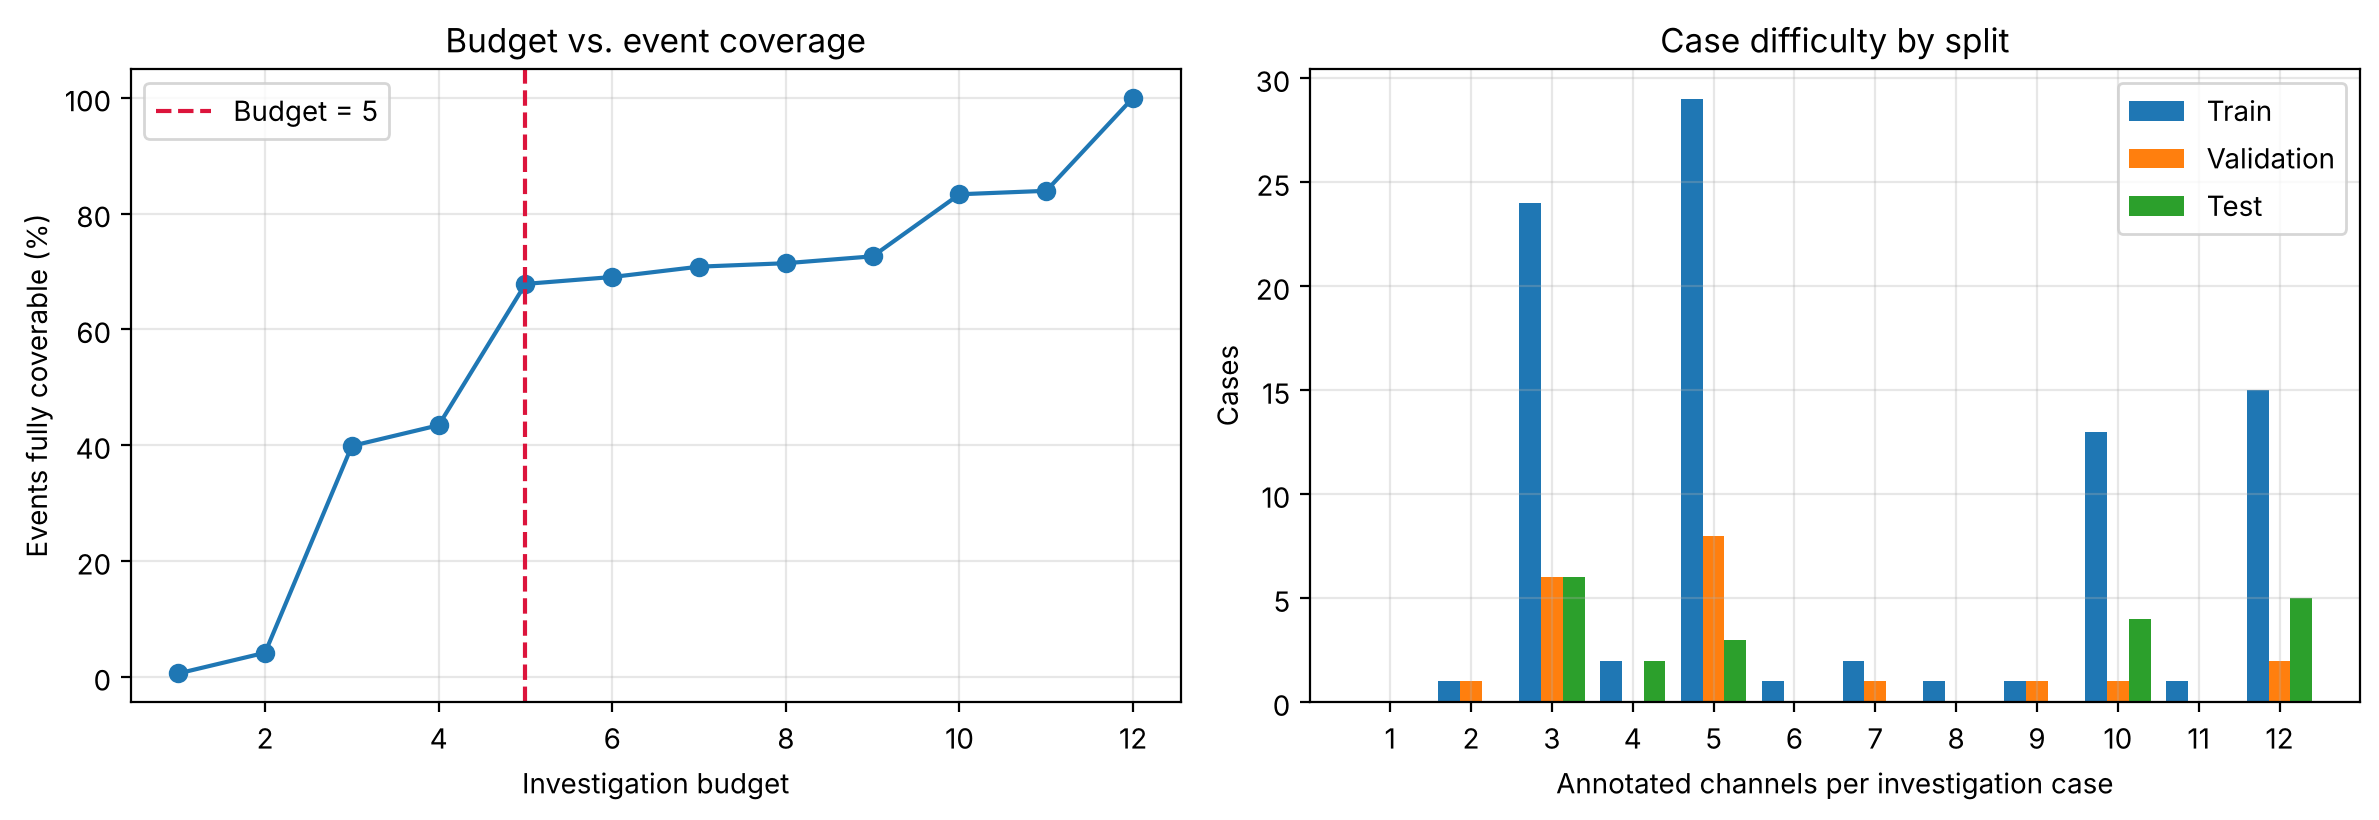

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
cnt = pd.Series([len(v) for v in event_sets.values()])
cov = [(cnt <= b).mean() * 100 for b in range(1, 13)]
ax[0].plot(range(1, 13), cov, marker="o"); ax[0].axvline(BUDGET, ls="--", color="crimson", label="Budget = 5")
ax[0].set_xlabel("Investigation budget"); ax[0].set_ylabel("Events fully coverable (%)"); ax[0].set_title("Budget vs. event coverage"); ax[0].legend()
for j, (s, c) in enumerate([("Train", case_tr), ("Validation", case_va), ("Test", case_te)]):
    vc = c.N_annotated.value_counts().reindex(range(1, 13), fill_value=0)
    ax[1].bar(np.arange(1, 13) + (j - 1) * 0.27, vc.values, 0.27, label=s)
ax[1].set_xticks(range(1, 13)); ax[1].set_xlabel("Annotated channels per investigation case"); ax[1].set_ylabel("Cases"); ax[1].set_title("Case difficulty by split"); ax[1].legend()
save_show("11_budget_coverage_and_case_sizes.png")

## 4. Environment check (state = 25, actions = 12, reward = ±1, 5 steps)

In [6]:
env = D.InvestigationEnv(S_tr, Y_tr, BUDGET)
s = env.reset(0)
print("Event:", case_tr.EventID[0], "| state size:", s.shape[0], "| annotated:", sorted(event_sets[case_tr.EventID[0]]))
for a in np.argsort(-S_tr[0])[:BUDGET]:
    s, r, done, hit = env.step(a)
    print(f"  investigate {CHANNELS[a]:11s} reward {r:+.0f}  remaining {env.remaining}  done {done}")
print("Status vector (0 / 0.5 / 1):", s[N_CH:2 * N_CH])

Event: id_1 | state size: 25 | annotated: ['channel_14', 'channel_15', 'channel_21', 'channel_22', 'channel_29', 'channel_31', 'channel_39', 'channel_41', 'channel_43', 'channel_45', 'channel_48', 'channel_52']
  investigate channel_41  reward +1  remaining 4  done False
  investigate channel_48  reward +1  remaining 3  done False
  investigate channel_52  reward +1  remaining 2  done False
  investigate channel_45  reward +1  remaining 1  done False
  investigate channel_43  reward +1  remaining 0  done True
Status vector (0 / 0.5 / 1): [1. 1. 1. 0. 0. 0. 1. 1. 0. 0. 0. 0.]


## 5. Train 5 DQN seeds in parallel

In [7]:
HP = dict(budget=BUDGET, hidden=64, lr=1e-3, gamma=0.95, batch=64, buffer=10000, episodes=3000,
          eps_start=1.0, eps_min=0.05, eps_decay=0.998, target_update=20, eval_every=50)
SEEDS = [0, 1, 2, 3, 4]
cfgs = [dict(HP, seed=s, train_scores=S_tr, train_targets=Y_tr, val_scores=S_va, val_targets=Y_va, out_dir=str(RL_DIR)) for s in SEEDS]
t0 = time.time()
with mp.get_context("spawn").Pool(len(SEEDS)) as pool:
    runs = pool.map(D.train_seed, cfgs)
print(f"Trained {len(runs)} seeds in parallel in {(time.time()-t0)/60:.1f} min")
for r_ in runs:
    print(f"  seed {r_['seed']}: best validation reward {r_['best_val_reward']:.3f} at episode {r_['best_episode']}")

I0000 00:00:1794214299.539241    3770 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794214299.537492    3768 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794214299.560638    3769 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794214299.563392    3771 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

I0000 00:00:1794214302.219517    3771 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794214302.352418    3770 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794214302.555258    3767 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794214302.602917    3768 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794214302.637040    3769 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Trained 5 seeds in parallel in 1.2 min
  seed 0: best validation reward 3.500 at episode 2050
  seed 1: best validation reward 3.500 at episode 1300
  seed 2: best validation reward 3.500 at episode 450
  seed 3: best validation reward 3.500 at episode 600
  seed 4: best validation reward 3.500 at episode 750


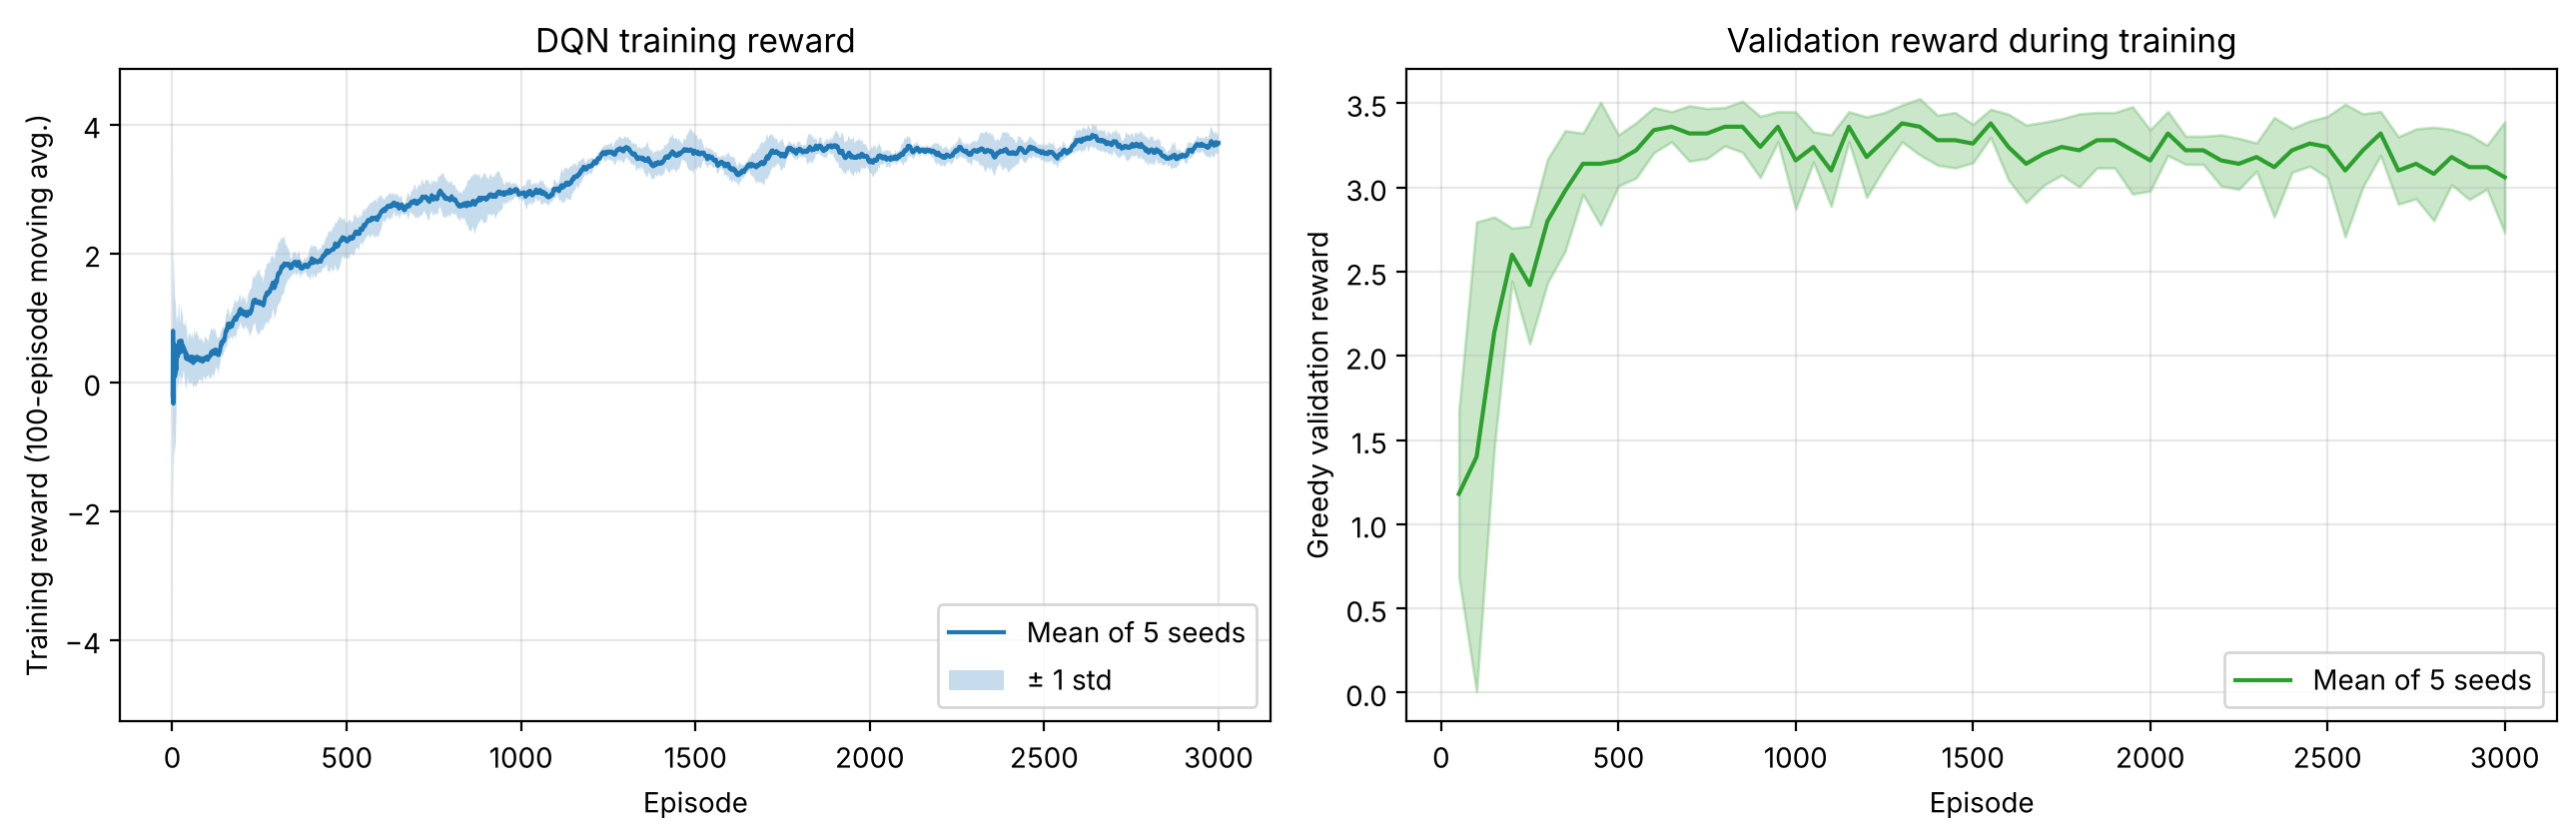

In [8]:
H = pd.concat([pd.DataFrame(r_["history"]).assign(Seed=r_["seed"]) for r_ in runs])
CK = pd.concat([pd.DataFrame(r_["checkpoints"]).assign(Seed=r_["seed"]) for r_ in runs])
H["Reward_MA100"] = H.groupby("Seed")["Reward"].transform(lambda x: x.rolling(100, min_periods=1).mean())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
g = H.groupby("Episode")["Reward_MA100"]; m, sdv = g.mean(), g.std()
ax[0].plot(m.index, m, label="Mean of 5 seeds"); ax[0].fill_between(m.index, m - sdv, m + sdv, alpha=0.25, label="± 1 std")
ax[0].set_xlabel("Episode"); ax[0].set_ylabel("Training reward (100-episode moving avg.)"); ax[0].set_title("DQN training reward"); ax[0].legend()
g = CK.groupby("Episode")["Validation_Reward"]; m, sdv = g.mean(), g.std()
ax[1].plot(m.index, m, color="C2", label="Mean of 5 seeds"); ax[1].fill_between(m.index, m - sdv, m + sdv, color="C2", alpha=0.25)
ax[1].set_xlabel("Episode"); ax[1].set_ylabel("Greedy validation reward"); ax[1].set_title("Validation reward during training"); ax[1].legend()
save_show("12_dqn_training_and_validation_reward.png")

## 6. Policies and evaluation
* **DQN** – greedy policy of the best validation checkpoint of each seed.
* **Random** – 5 distinct channels uniformly at random (expected value over 1 000 draws per case).
* **Fixed priority** – channels ranked by how often they are annotated in *training* cases.
* **LSTM-greedy** (additional) – the 5 channels with the largest reconstruction errors.
* **Oracle** (upper bound) – annotated channels first.

In [9]:
freq = Y_tr.sum(0); fixed_order = list(np.argsort(-freq, kind="stable"))
print("Fixed-priority ranking:", [f"{CHANNELS[i]}({freq[i]})" for i in fixed_order])

def static_rows(order_fn, S, Y):
    return [dict(D.episode_metrics(np.array(order_fn(i, S, Y)), Y[i]), Selected=list(order_fn(i, S, Y))) for i in range(len(S))]
policies = {
    "Fixed Priority": lambda i, S, Y: fixed_order[:BUDGET],
    "LSTM-Greedy": lambda i, S, Y: list(np.argsort(-S[i], kind="stable")[:BUDGET]),
    "Oracle": lambda i, S, Y: list(np.argsort(~Y[i], kind="stable")[:BUDGET]),
}
def random_rows(S, Y, n=1000, seed=SEED):
    rng = np.random.RandomState(seed); out = []
    for i in range(len(S)):
        sims = [D.episode_metrics(rng.choice(N_CH, BUDGET, replace=False), Y[i]) for _ in range(n)]
        out.append({k: float(np.mean([x[k] for x in sims])) for k in sims[0]})
    return out

qs = []
for r_ in runs:
    q = D.build_q_network(tf); q.set_weights(r_["weights"]); qs.append(q)

def evaluate_split(case_df, S, Y):
    per_case = []
    for k, q in zip(SEEDS, qs):
        rows = D.evaluate(lambda x: q(x, training=False).numpy(), S, Y, BUDGET)
        per_case += [dict(r, Method="DQN", Seed=k, EventID=e) for r, e in zip(rows, case_df.EventID)]
    for name, fn in policies.items():
        per_case += [dict(r, Method=name, Seed=-1, EventID=e) for r, e in zip(static_rows(fn, S, Y), case_df.EventID)]
    per_case += [dict(r, Method="Random", Seed=-1, EventID=e) for r, e in zip(random_rows(S, Y), case_df.EventID)]
    df = pd.DataFrame(per_case); df["N_annotated"] = df.EventID.map(lambda e: len(event_sets[e]))
    det = df[df.Method != "Random"]
    assert np.allclose(det.TotalReward, 2 * det.Hits - BUDGET), "reward / hits mismatch"
    assert (det.Steps == BUDGET).all()
    return df

ev_val = evaluate_split(case_va, S_va, Y_va)
ev_test = evaluate_split(case_te, S_te, Y_te)
print("Consistency check passed: reward = 2*hits - 5 for every evaluated episode")

METRICS = ["TotalReward", "Hits", "Precision_at_5", "Recall_at_5", "UnnecessaryInvestigations"]
ORDER = ["DQN", "Fixed Priority", "LSTM-Greedy", "Random", "Oracle"]
def summarise(df):
    out = []
    for mth in ORDER:
        d = df[df.Method == mth]
        if mth == "DQN":
            per_seed = d.groupby("Seed")[METRICS].mean()
            row = {f"{k}": per_seed[k].mean() for k in METRICS}; row.update({f"{k}_std": per_seed[k].std(ddof=0) for k in METRICS})
        else:
            row = {k: d[k].mean() for k in METRICS}; row.update({f"{k}_std": 0.0 for k in METRICS})
        out.append({"Method": mth, "Cases": d.EventID.nunique(), **row})
    return pd.DataFrame(out)

val_cmp, test_cmp = summarise(ev_val), summarise(ev_test)
sub = lambda df: df[df.N_annotated < 12]
test_cmp_sub = summarise(sub(ev_test)); val_cmp_sub = summarise(sub(ev_val))
show = lambda t: t[["Method", "Cases"] + METRICS + ["TotalReward_std", "Precision_at_5_std", "Recall_at_5_std"]].round(4).to_string(index=False)
print("VALIDATION (all cases)\n" + show(val_cmp))
print("\nTEST (all cases)\n" + show(test_cmp))
print("\nTEST (excluding 12-channel events)\n" + show(test_cmp_sub))

Fixed-priority ranking: ['channel_41(67)', 'channel_45(67)', 'channel_43(66)', 'channel_14(54)', 'channel_21(54)', 'channel_29(53)', 'channel_48(48)', 'channel_52(46)', 'channel_22(34)', 'channel_31(33)', 'channel_39(32)', 'channel_15(31)']


Consistency check passed: reward = 2*hits - 5 for every evaluated episode
VALIDATION (all cases)
        Method  Cases  TotalReward   Hits  Precision_at_5  Recall_at_5  UnnecessaryInvestigations  TotalReward_std  Precision_at_5_std  Recall_at_5_std
           DQN     20       3.5000 4.2500          0.8500       0.8802                     0.7500              0.0                 0.0              0.0
Fixed Priority     20       0.7000 2.8500          0.5700       0.5448                     2.1500              0.0                 0.0              0.0
   LSTM-Greedy     20       2.7000 3.8500          0.7700       0.7602                     1.1500              0.0                 0.0              0.0
        Random     20      -0.4214 2.2893          0.4579       0.4160                     2.7107              0.0                 0.0              0.0
        Oracle     20       3.5000 4.2500          0.8500       0.8802                     0.7500              0.0                 0.0         

## 7. Statistical comparison on the test set (paired Wilcoxon signed-rank, per case)
DQN hits are averaged over the 5 seeds for each case.

In [10]:
dqn_case = ev_test[ev_test.Method == "DQN"].groupby("EventID")["Hits"].mean()
stat_rows = []
for other in ["Fixed Priority", "LSTM-Greedy", "Random"]:
    o = ev_test[ev_test.Method == other].set_index("EventID")["Hits"].reindex(dqn_case.index)
    diff = dqn_case - o
    p = wilcoxon(dqn_case, o, zero_method="zsplit").pvalue if np.any(diff != 0) else 1.0
    stat_rows.append({"Comparison": f"DQN vs {other}", "Mean_hit_difference": diff.mean(),
                      "DQN_better": int((diff > 0).sum()), "Equal": int((diff == 0).sum()), "DQN_worse": int((diff < 0).sum()),
                      "Wilcoxon_p": p})
stat_df = pd.DataFrame(stat_rows); print(stat_df.round(4).to_string(index=False))

           Comparison  Mean_hit_difference  DQN_better  Equal  DQN_worse  Wilcoxon_p
DQN vs Fixed Priority               0.4400          10      6          4      0.0800
   DQN vs LSTM-Greedy               0.1400           5     12          3      0.4904
        DQN vs Random               1.1466          13      5          2      0.0020


## 8. Result plots

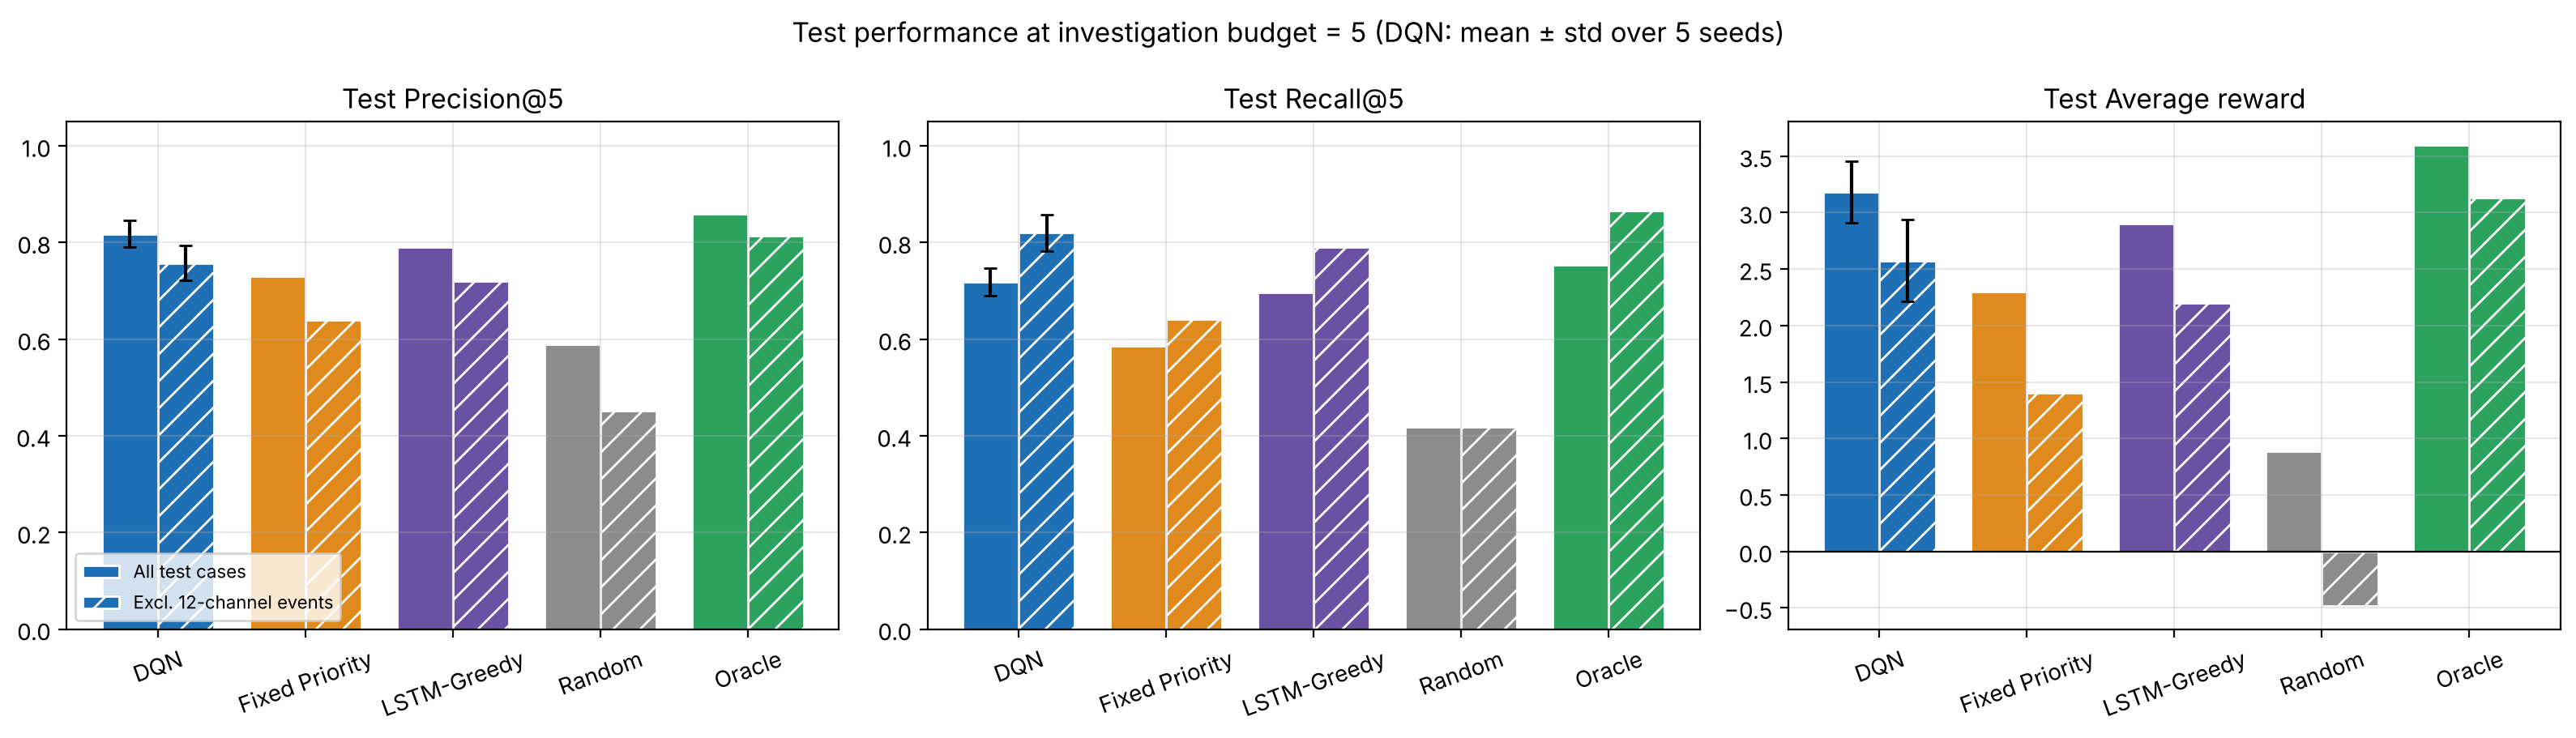

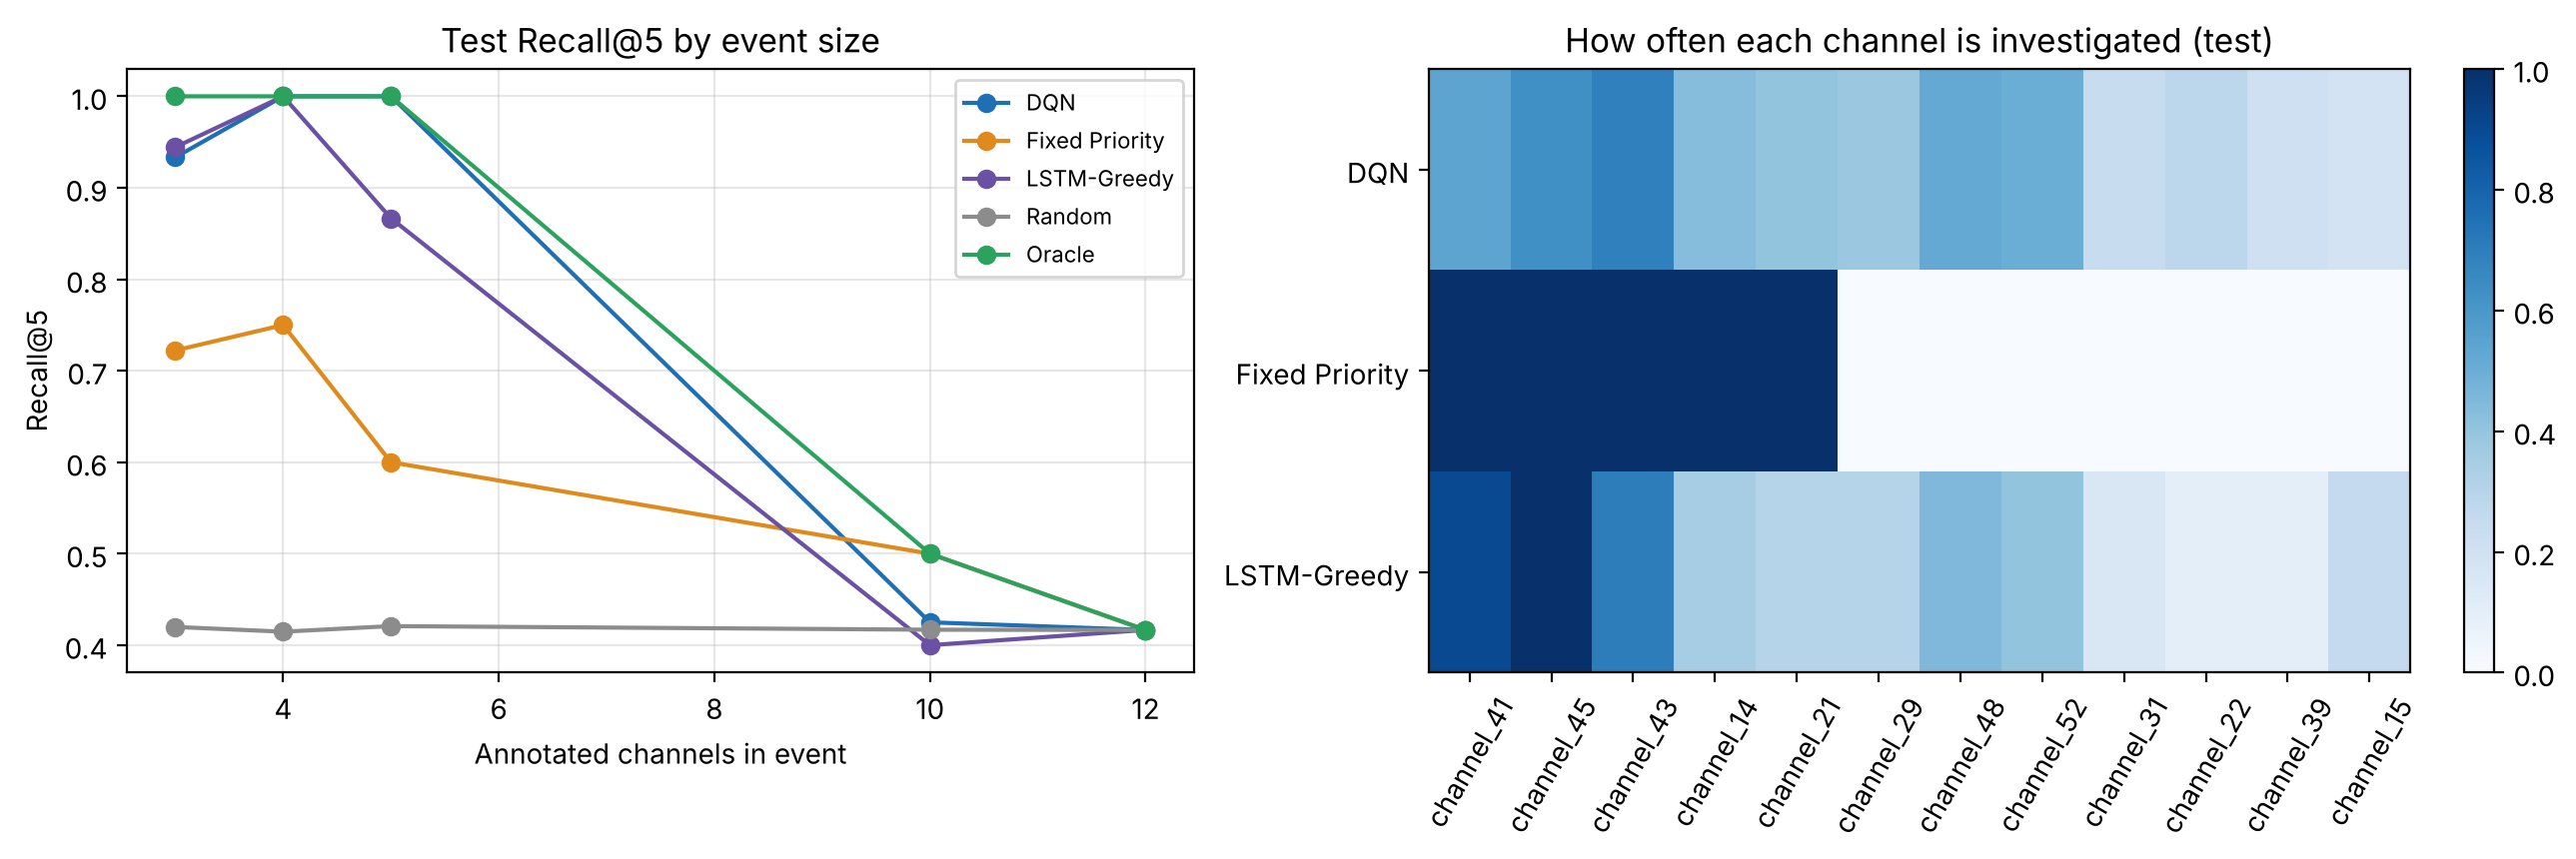

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
colors = {"DQN": "#1f6fb4", "Fixed Priority": "#e08a1e", "LSTM-Greedy": "#6a51a3", "Random": "#8c8c8c", "Oracle": "#2ca25f"}
for a, (metric, title) in zip(ax, [("Precision_at_5", "Precision@5"), ("Recall_at_5", "Recall@5"), ("TotalReward", "Average reward")]):
    for j, (tbl, lab, hatch) in enumerate([(test_cmp, "All test cases", ""), (test_cmp_sub, "Excl. 12-channel events", "//")]):
        a.bar(np.arange(len(ORDER)) + (j - 0.5) * 0.38, tbl[metric], 0.38, yerr=tbl[f"{metric}_std"].where(tbl[f"{metric}_std"] > 0), capsize=3,
              color=[colors[m] for m in tbl.Method], hatch=hatch, edgecolor="white", label=lab)
    a.set_xticks(range(len(ORDER)), ORDER, rotation=20); a.set_title(f"Test {title}")
    if metric != "TotalReward": a.set_ylim(0, 1.05)
    else: a.axhline(0, color="black", lw=0.8)
ax[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Test performance at investigation budget = 5 (DQN: mean ± std over 5 seeds)")
save_show("13_test_performance_comparison.png")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for mth in ["DQN", "Fixed Priority", "LSTM-Greedy", "Random", "Oracle"]:
    d = ev_test[ev_test.Method == mth].groupby("N_annotated")["Recall_at_5"].mean()
    ax[0].plot(d.index, d.values, marker="o", label=mth, color=colors[mth])
ax[0].set_xlabel("Annotated channels in event"); ax[0].set_ylabel("Recall@5"); ax[0].set_title("Test Recall@5 by event size"); ax[0].legend(fontsize=8)
sel = np.zeros((3, N_CH))
for j, mth in enumerate(["DQN", "Fixed Priority", "LSTM-Greedy"]):
    for lst in ev_test[ev_test.Method == mth].Selected: sel[j, list(lst)] += 1
    sel[j] /= len(ev_test[ev_test.Method == mth])
im = ax[1].imshow(sel, aspect="auto", cmap="Blues", vmin=0, vmax=1); ax[1].grid(False)
ax[1].set_yticks(range(3), ["DQN", "Fixed Priority", "LSTM-Greedy"]); ax[1].set_xticks(range(N_CH), CHANNELS, rotation=60)
ax[1].set_title("How often each channel is investigated (test)"); plt.colorbar(im, ax=ax[1], fraction=0.03)
save_show("14_recall_by_event_size_and_channel_selection.png")

## 9. Save Course 3 outputs

In [12]:
win.to_parquet(RL_DIR / "lstm_window_scores.parquet")
cases.to_csv(RL_DIR / "investigation_cases.csv", index=False)
det_summary.to_csv(RL_DIR / "lstm_event_detection_by_split.csv")
H.drop(columns="Reward_MA100").to_csv(RL_DIR / "dqn_training_history_all_seeds.csv", index=False)
CK.to_csv(RL_DIR / "dqn_validation_checkpoints_all_seeds.csv", index=False)
pd.DataFrame([{k: r_[k] for k in ["seed", "best_episode", "best_val_reward", "model_path"]} for r_ in runs]) \
  .assign(model_path=lambda d: d.model_path.map(lambda p: Path(p).name)).to_csv(RL_DIR / "dqn_seed_summary.csv", index=False)
named = lambda df: df.assign(Selected=df.Selected.map(lambda l: [CHANNELS[int(i)] for i in l] if isinstance(l, (list, np.ndarray)) else ""))
named(ev_val).to_csv(RES / "per_case_results_validation.csv", index=False)
named(ev_test).to_csv(RES / "per_case_results_test.csv", index=False)
val_cmp.to_csv(RES / "validation_comparison.csv", index=False); test_cmp.to_csv(RES / "test_comparison.csv", index=False)
val_cmp_sub.to_csv(RES / "validation_comparison_excl_12ch.csv", index=False); test_cmp_sub.to_csv(RES / "test_comparison_excl_12ch.csv", index=False)
stat_df.to_csv(RES / "test_statistical_tests.csv", index=False)
pd.DataFrame({"Parameter": list(HP) + ["seeds", "state", "fixed_priority_order"],
              "Value": list(HP.values()) + [SEEDS, "12 log1p channel errors + 12 status (0/0.5/1) + remaining budget/5",
                                             [CHANNELS[i] for i in fixed_order]]}).to_csv(RES / "experiment_configuration.csv", index=False)
for d in [RL_DIR, RES]:
    for f in sorted(d.iterdir()): print(f"{d.name}/{f.name:45s} {f.stat().st_size/1e3:9.1f} KB")

06_rl_dqn/dqn_seed0.keras                                    45.0 KB
06_rl_dqn/dqn_seed1.keras                                    45.0 KB
06_rl_dqn/dqn_seed2.keras                                    45.0 KB
06_rl_dqn/dqn_seed3.keras                                    45.0 KB
06_rl_dqn/dqn_seed4.keras                                    45.0 KB
06_rl_dqn/dqn_seed_summary.csv                                0.2 KB
06_rl_dqn/dqn_training_history_all_seeds.csv                636.4 KB
06_rl_dqn/dqn_validation_checkpoints_all_seeds.csv            3.2 KB
06_rl_dqn/investigation_cases.csv                            42.7 KB
06_rl_dqn/lstm_event_detection_by_split.csv                   0.1 KB
06_rl_dqn/lstm_window_scores.parquet                       3883.6 KB
07_results/experiment_configuration.csv                        0.5 KB
07_results/per_case_results_test.csv                          20.6 KB
07_results/per_case_results_validation.csv                    20.6 KB
07_results/test_comparison.csv 